In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Problema 1

In [3]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [4]:
pregunta_1 = "1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  "
pregunta_2 = "2. A y C son consecutivas y tienen la misma holgura total. El responsable de A pide retrasarla 3 semanas y el de C también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  "
pregunta_3 = "3. Compruébelo: recalcule el calendario con A retrasada 3 semanas y después con las dos retrasadas.  "
pregunta_4 = "4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 3 semanas entre A y C?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

2. A y C son consecutivas y tienen la misma holgura total. El responsable de A pide retrasarla 3 semanas y el de C también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

3. Compruébelo: recalcule el calendario con A retrasada 3 semanas y después con las dos retrasadas.  

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 3 semanas entre A y C?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado-p1
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 1       ),
    ('B'     , '---'      , 8       ),
    ('C'     , 'A'        , 4       ),
    ('D'     , 'A'        , 2       ),
    ('E'     , 'B,C,D'    , 8       ),
    ('F'     , 'D'        , 2       ),
    ('G'     , 'C,F'      , 1       ),
    ('H'     , 'E'        , 2       ),
    ('I'     , 'F,H'      , 2       ),
    ('J'     , 'G,I'      , 7       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,1
B,---,8
C,A,4
D,A,2
E,"B,C,D",8
F,D,2
G,"C,F",1
H,E,2
I,"F,H",2


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones-p1
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
    'I': 'Pruebas de integración',
    'J': 'Pruebas con usuarios',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización
I,Pruebas de integración
J,Pruebas con usuarios


## Solución del problema 1

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

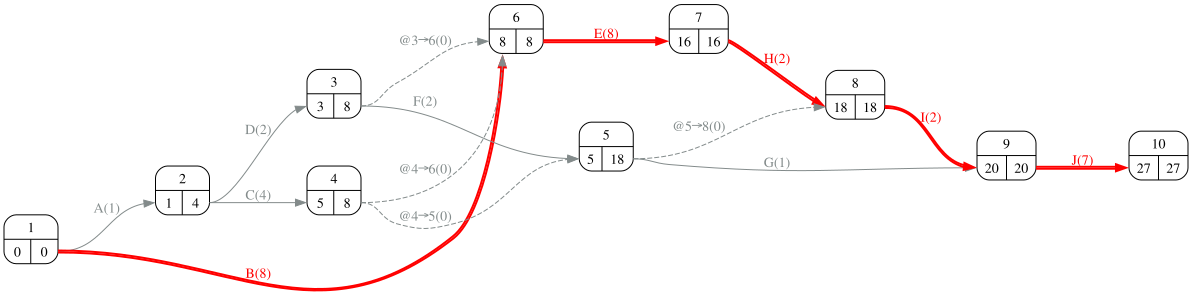

In [9]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert-p1
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario-p1
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,3,1,4,0,0,3,1
B,0,0,8,8,0,0,0,8
C,1,4,5,8,0,0,3,4
D,1,6,3,8,0,0,5,2
E,8,8,16,16,0,0,0,8
F,3,16,5,18,0,0,13,2
G,5,19,6,20,14,1,14,1
H,16,16,18,18,0,0,0,2
I,18,18,20,20,0,0,0,2


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. A y C son consecutivas y tienen la misma holgura total. El responsable de A pide retrasarla 3 semanas y el de C también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

No. La holgura total de A y la de C son la *misma* holgura: la de la cadena en la que están. A tiene holgura libre cero, así que cualquier retraso suyo mueve el inicio de C y le consume holgura. Si A gasta las 3 semanas, C se queda sin ninguna; si además C se retrasa, el proyecto se alarga.

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Compruébelo: recalcule el calendario con A retrasada 3 semanas y después con las dos retrasadas.  

In [13]:
X, Y, h = 'A', 'C', 3
d1 = datos_proyecto['duration'].copy(); d1[X] += h
d2 = d1.copy(); d2[Y] += h
cal1, cal2 = proyecto.calendar(d1), proyecto.calendar(d2)
pd.DataFrame({'original': calendario.loc[[X, Y], 'H_total'], f'{X} retrasada {h}': cal1.loc[[X, Y], 'H_total'],
              'las dos retrasadas': cal2.loc[[X, Y], 'H_total']})

,original,A retrasada 3,las dos retrasadas
activity,,,
A,3,0,0
C,3,0,0


In [14]:
Markdown(f'Duración del proyecto: {duracion_proyecto} semanas en la planificación original, {proyecto.duration(d1)} con {X} retrasada '
         f'y **{proyecto.duration(d2)}** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.')

Duración del proyecto: 27 semanas en la planificación original, 27 con A retrasada y **30** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 3 semanas entre A y C?  

In [16]:
Markdown(f'''La holgura libre de {X} es {int(calendario.loc[X, "H_libre"])}: es lo que puede retrasarse sin mover a {Y}. La holgura independiente de {Y} es {int(calendario.loc[Y, "H_independiente"])}: lo que puede retrasarse {Y} aunque {X} acabe lo más tarde posible. Las {h} semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ {h} entre {X} y {Y} respeta el plazo; lo que no es posible es que cada una disponga de {h} por su cuenta.''')

La holgura libre de A es 0: es lo que puede retrasarse sin mover a C. La holgura independiente de C es 0: lo que puede retrasarse C aunque A acabe lo más tarde posible. Las 3 semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ 3 entre A y C respeta el plazo; lo que no es posible es que cada una disponga de 3 por su cuenta.

# Problema 2

In [17]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [18]:
pregunta_1 = "1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  "
pregunta_2 = "2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  "
pregunta_3 = "3. ¿Qué probabilidad hay de terminar el proyecto en 36 semanas o menos?  "
pregunta_4 = "4. ¿Qué probabilidad hay de terminar entre las semanas 33 y 36?  "
pregunta_5 = "5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  "
pregunta_6 = "6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

3. ¿Qué probabilidad hay de terminar el proyecto en 36 semanas o menos?  

4. ¿Qué probabilidad hay de terminar entre las semanas 33 y 36?  

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  

In [19]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado-p2
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 5       , 1                 ),
    ('B'     , '---'      , 5       , 0.8               ),
    ('C'     , 'A,B'      , 4       , 0.1               ),
    ('D'     , 'A'        , 4       , 1                 ),
    ('E'     , 'C'        , 8       , 0.3               ),
    ('F'     , 'E'        , 8       , 0.8               ),
    ('G'     , 'F'        , 3       , 0.6               ),
    ('H'     , 'F'        , 6       , 0.2               ),
    ('I'     , 'G,H'      , 3       , 0.4               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,5,1.0
B,---,5,0.8
C,"A,B",4,0.1
D,A,4,1.0
E,C,8,0.3
F,E,8,0.8
G,F,3,0.6
H,F,6,0.2
I,"G,H",3,0.4


## Solución del problema 2

In [20]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [21]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

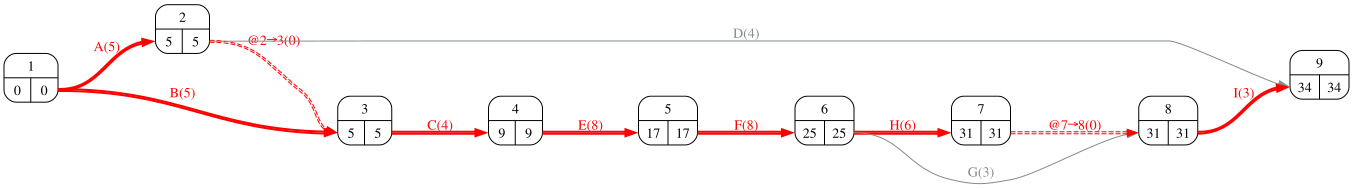

In [22]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert-p2
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [23]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras-p2
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['activities'].T

,@2→3,@7→8,A,B,C,D,E,F,G,H,I
H_total,0,0,0,0,0,25,0,0,3,0,0


In [24]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración media del proyecto es {duracion_media} semanas y tiene {len(rutas_criticas)} ruta(s) crítica(s).')

Route_2: A - C - E - F - H - I
Route_5: B - C - E - F - H - I


La duración media del proyecto es 34 semanas y tiene 2 ruta(s) crítica(s).

## Apartado 2

In [25]:
display(Markdown(pregunta_2))

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

Por el teorema central del límite, la duración de una ruta es aproximadamente normal con media la suma de las medias y varianza la suma de las varianzas de sus actividades. Para el proyecto se toma la ruta crítica; si hay varias, la de mayor varianza, que es la hipótesis más prudente (la verdadera distribución del máximo de varias rutas no es normal, y el método PERT la aproxima así).

In [26]:
#| tbl-cap: "Varianza de las rutas críticas"
#| label: tbl-varianzaRutas-p2
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'],
                                                                   variances=datos_proyecto['variance'])
varianza_rutas

,Activities,Variance
Route_2,"A, C, E, F, H, I",1.94
Route_5,"B, C, E, F, H, I",1.58


In [27]:
Markdown(f'La varianza del proyecto es {desviacion_proyecto**2:.3f} y su desviación típica {desviacion_proyecto:.3f} semanas.')

La varianza del proyecto es 1.940 y su desviación típica 1.393 semanas.

## Apartado 3

In [28]:
display(Markdown(pregunta_3))

3. ¿Qué probabilidad hay de terminar el proyecto en 36 semanas o menos?  

Con $T \sim N(\mu, \sigma)$: $P(T \le t) = \Phi\left(\frac{t - \mu}{\sigma}\right)$.

In [29]:
plazo = 36
z = (plazo - duracion_media) / desviacion_proyecto
probabilidad_plazo = norm.cdf(z)
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}, luego P(T ≤ {plazo}) = Φ({z:.3f}) = {probabilidad_plazo:.4f} ({probabilidad_plazo*100:.1f} %).')

z = (36 − 34) / 1.393 = 1.436, luego P(T ≤ 36) = Φ(1.436) = 0.9245 (92.4 %).

## Apartado 4

In [30]:
display(Markdown(pregunta_4))

4. ¿Qué probabilidad hay de terminar entre las semanas 33 y 36?  

In [31]:
t_a, t_b = 33, 36
p_b = norm.cdf((t_b - duracion_media) / desviacion_proyecto)
p_a = norm.cdf((t_a - duracion_media) / desviacion_proyecto)
Markdown(f'P({t_a} < T ≤ {t_b}) = Φ({(t_b - duracion_media) / desviacion_proyecto:.3f}) − Φ({(t_a - duracion_media) / desviacion_proyecto:.3f}) '
         f'= {p_b:.4f} − {p_a:.4f} = {p_b - p_a:.4f} ({(p_b - p_a)*100:.1f} %).')

P(33 < T ≤ 36) = Φ(1.436) − Φ(-0.718) = 0.9245 − 0.2364 = 0.6881 (68.8 %).

## Apartado 5

In [32]:
display(Markdown(pregunta_5))

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  

Se busca $t$ tal que $P(T \le t) = p$, es decir, $t = \mu + z_p\,\sigma$ con $z_p = \Phi^{-1}(p)$.

In [33]:
probabilidad_objetivo = 0.95
z_p = norm.ppf(probabilidad_objetivo)
duracion_comprometida = duracion_media + z_p * desviacion_proyecto
Markdown(f'z = {z_p:.3f}; t = {duracion_media} + {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_comprometida:.2f} semanas. '
         f'Como el calendario se mide en semanas enteras, se comprometerían {int(np.ceil(duracion_comprometida))} semanas.')

z = 1.645; t = 34 + 1.645 × 1.393 = 36.29 semanas. Como el calendario se mide en semanas enteras, se comprometerían 37 semanas.

## Apartado 6

In [34]:
display(Markdown(pregunta_6))

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  

In [35]:
Markdown(f'''La duración media es la mediana de la normal, así que P(T ≤ {duracion_media}) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 95% haría falta que la media del proyecto fuera {duracion_media} − {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_media - z_p * desviacion_proyecto:.2f} semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.''')

La duración media es la mediana de la normal, así que P(T ≤ 34) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 95% haría falta que la media del proyecto fuera 34 − 1.645 × 1.393 = 31.71 semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.

# Problema 3

In [36]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones, duraciones normal y tope (semanas) y coste unitario de reducción (k€/semana) se adjunta. Las actividades con CUR infinito no pueden acelerarse.

In [37]:
pregunta_1 = "1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  "
pregunta_2 = "2. La actividad crítica más barata de acelerar es B. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  "
pregunta_3 = "3. Compruébelo: acorte B una semana y recalcule la duración.  "
pregunta_4 = "4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  

2. La actividad crítica más barata de acelerar es B. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  

3. Compruébelo: acorte B una semana y recalcule la duración.  

4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  

In [38]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado-p3
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 3       , 3           , np.inf),
    ('B'     , '---'      , 3       , 1           , 1     ),
    ('C'     , '---'      , 2       , 1           , 1     ),
    ('D'     , 'A,B,C'    , 8       , 6           , 9     ),
    ('E'     , 'D'        , 3       , 3           , np.inf),
    ('F'     , 'B'        , 2       , 2           , np.inf),
    ('G'     , 'E,F'      , 6       , 4           , 9     ),
    ('H'     , 'E'        , 6       , 3           , 2     ),
    ('I'     , 'G'        , 7       , 7           , np.inf),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,3,3,inf
B,---,3,1,1.0
C,---,2,1,1.0
D,"A,B,C",8,6,9.0
E,D,3,3,inf
F,B,2,2,inf
G,"E,F",6,4,9.0
H,E,6,3,2.0
I,G,7,7,inf


## Solución del problema 3

In [39]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)

## Apartado 1

In [40]:
display(Markdown(pregunta_1))

1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  

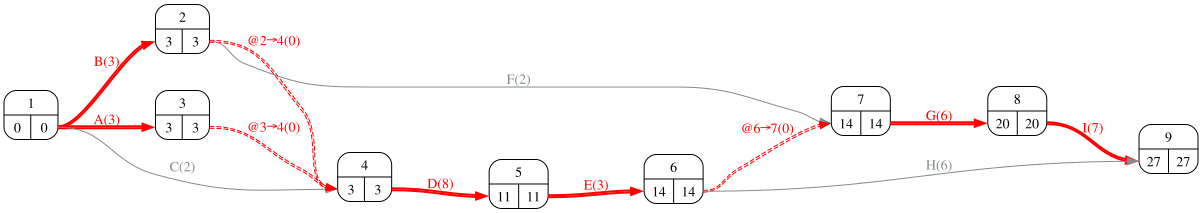

In [41]:
#| fig-cap: "Grafo PERT con las duraciones normales y las rutas críticas"
#| label: fig-pert-p3
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [42]:
duracion_normal = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
comunes = set.intersection(*[set(a) for a in rutas_criticas.values()])
Markdown(f'Duración {duracion_normal} semanas con {len(rutas_criticas)} rutas críticas; actividades comunes a todas: {", ".join(sorted(comunes)) or "ninguna"}.')

Route_1: A - D - E - G - I
Route_3: B - D - E - G - I


Duración 27 semanas con 2 rutas críticas; actividades comunes a todas: D, E, G, I.

## Apartado 2

In [43]:
display(Markdown(pregunta_2))

2. La actividad crítica más barata de acelerar es B. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  

No funcionará: B está en una sola de las rutas críticas. Al acortarla, esa ruta se acorta, pero la otra sigue midiendo lo mismo y el proyecto también. Para reducir el proyecto hay que acortar *todas* las rutas críticas a la vez: una actividad común, o una actividad de cada ruta.

## Apartado 3

In [44]:
display(Markdown(pregunta_3))

3. Compruébelo: acorte B una semana y recalcule la duración.  

In [45]:
barata = 'B'
d1 = datos_proyecto['duration'].copy(); d1[barata] -= 1
Markdown(f'Acortando {barata} una semana la duración del proyecto es {proyecto.duration(d1)} semanas (antes {duracion_normal}): '
         f'se han gastado {datos_proyecto.loc[barata, "ucr"]:.0f} k€ para nada; la ruta {[r for r, a in rutas_criticas.items() if barata not in a][0]} sigue siendo crítica.')

Acortando B una semana la duración del proyecto es 27 semanas (antes 27): se han gastado 1 k€ para nada; la ruta Route_1 sigue siendo crítica.

## Apartado 4

In [46]:
display(Markdown(pregunta_4))

4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  

In [47]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff-p3
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=2, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2
Route_1,inf,,,9.0,inf,,9.0,,inf,27.0,26.0,25.0
Route_2,inf,,,9.0,inf,,,2.0,,20.0,19.0,18.0
Route_3,,1.0,,9.0,inf,,9.0,,inf,27.0,26.0,25.0
Route_4,,1.0,,9.0,inf,,,2.0,,20.0,19.0,18.0
Route_5,,1.0,,,,inf,9.0,,inf,18.0,18.0,18.0
Route_6,,,1.0,9.0,inf,,9.0,,inf,26.0,25.0,24.0
Route_7,,,1.0,9.0,inf,,,2.0,,19.0,18.0,17.0
0,0.0,2.0,1.0,2.0,0.0,0.0,2.0,3.0,0.0,,,
1,0.0,2.0,1.0,1.0,0.0,0.0,2.0,3.0,0.0,,,
2,0.0,2.0,1.0,0.0,0.0,0.0,2.0,3.0,0.0,,,


In [48]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'coste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen

,actividades acortadas,coste del paso
paso,,
1,D,9.0
2,D,9.0


In [49]:
mas_barata_comun = min(comunes, key=lambda a: datos_proyecto.loc[a, 'ucr']) if comunes else None
pareja = sorted(set(a for r, acts in rutas_criticas.items() for a in acts) - comunes, key=lambda a: datos_proyecto.loc[a, 'ucr'])
Markdown(f'''En cada paso el algoritmo compara el coste de la actividad común más barata ({mas_barata_comun}: {datos_proyecto.loc[mas_barata_comun, "ucr"]:.0f} k€) con el de la pareja más barata que cubre las dos rutas, y elige la opción de menor coste *que reduzca todas las rutas críticas*. {barata} sola nunca es candidata, por barata que sea, salvo emparejada con una actividad de la otra ruta.''')

En cada paso el algoritmo compara el coste de la actividad común más barata (D: 9 k€) con el de la pareja más barata que cubre las dos rutas, y elige la opción de menor coste *que reduzca todas las rutas críticas*. B sola nunca es candidata, por barata que sea, salvo emparejada con una actividad de la otra ruta.

In [50]:
Markdown(f'Duración final {proyecto.duration(duraciones_reducidas)} semanas, sobrecoste total {resumen["coste del paso"].sum():.0f} k€.')

Duración final 25 semanas, sobrecoste total 18 k€.

# Problema 4

In [51]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [52]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado-p4
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 7       , 40 ),
    ('B'     , '---'      , 6       , 20 ),
    ('C'     , 'A,B'      , 2       , 10 ),
    ('D'     , 'A,B'      , 2       , 40 ),
    ('E'     , 'B'        , 8       , 20 ),
    ('F'     , 'C'        , 1       , 30 ),
    ('G'     , 'D,F'      , 6       , 40 ),
    ('H'     , 'E,G'      , 4       , 60 ),
    ('I'     , 'H'        , 2       , 20 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,7,40
B,---,6,20
C,"A,B",2,10
D,"A,B",2,40
E,B,8,20
F,C,1,30
G,"D,F",6,40
H,"E,G",4,60
I,H,2,20


Al final de la semana 11 se realiza un punto de control. Para cada actividad se anotan las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [53]:
#| tbl-cap: "Datos del punto de control (final de la semana 11)"
#| label: tbl-seguimiento-p4
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 10             , 48, 100      ),
    ('B'     , 6              , 22, 100      ),
    ('C'     , 1              , 6 , 50       ),
    ('D'     , 1              , 10, 25       ),
    ('E'     , 5              , 12, 42       ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,10,48,100
B,6,22,100
C,1,6,50
D,1,10,25
E,5,12,42
F,0,0,0
G,0,0,0
H,0,0,0
I,0,0,0


In [54]:
pregunta_1 = "1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  "
pregunta_2 = "2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  "
pregunta_3 = "3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  "
pregunta_4 = "4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  

2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  

3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  

4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  

## Solución del problema 4

In [55]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

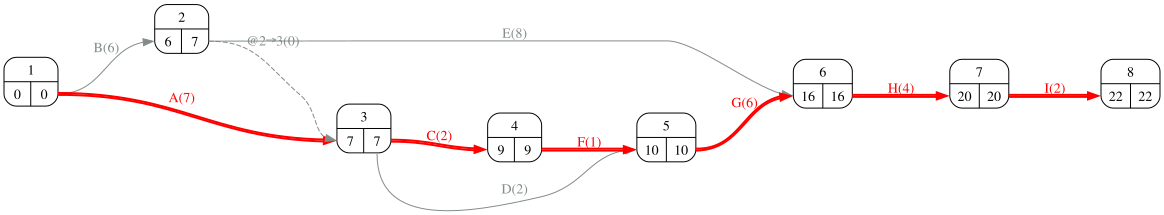

In [56]:
#| fig-cap: "Grafo PERT de la planificación"
#| label: fig-pert-p4
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

## Apartado 1

In [57]:
display(Markdown(pregunta_1))

1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  

En el Gantt del valor planificado cada casilla lleva el coste planificado de la semana (BAC / duración). En el del valor ganado, el BAC multiplicado por el porcentaje realizado se reparte entre las semanas trabajadas. En el del coste real, el coste incurrido entre las semanas trabajadas.

In [58]:
datos_valor_ganado = pd.concat([datos_proyecto, seguimiento], axis=1)
vg = EarnedValue(proyecto)
gantts = vg.calcula_gantts(datos_valor_ganado, planned_durations_label='duration',
                           actual_durations_label='actual_duration', PV_label='BAC', AC_label='AC',
                           percentage_complete_label='performed', tikz=True,
                           params=dict(period_width=1, row_height=0.7, activity_relative_height=0.6, **GANTT_PARAMS,
                                       critical_background_color='white!90!green', regular_background_color='white!90!green',
                                       regular_text_color='black', critical_text_color='black'))

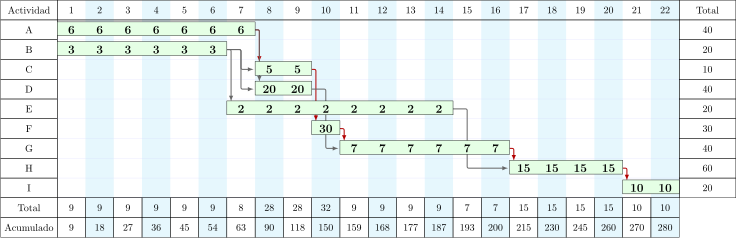

In [59]:
#| fig-cap: "PV: valor planificado"
#| label: fig-ganttPV-p4
pinta_tikz(gantts['gantt_PV'])

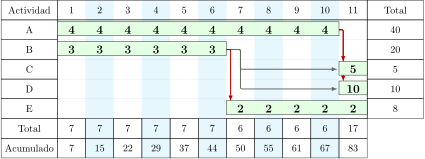

In [60]:
#| fig-cap: "EV: valor ganado"
#| label: fig-ganttEV-p4
pinta_tikz(gantts['gantt_EV'])

In [61]:
semana_control = 11
acumulados = gantts['acumulados']
PV = float(acumulados.loc[semana_control, 'PV'])
EV = float((datos_valor_ganado['BAC'] * datos_valor_ganado['performed'] / 100).sum())
AC = float(datos_valor_ganado['AC'].sum())
CV, SV = EV - AC, EV - PV
CPI, SPI = EV / AC, EV / PV
pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': CV, 'SV': SV, 'CPI': CPI, 'SPI': SPI, 'BAC': BAC_total}).round(3).to_frame('valor').T

,PV,EV,AC,CV,SV,CPI,SPI,BAC
valor,159.167,83.4,98.0,-14.6,-75.767,0.851,0.524,280.0


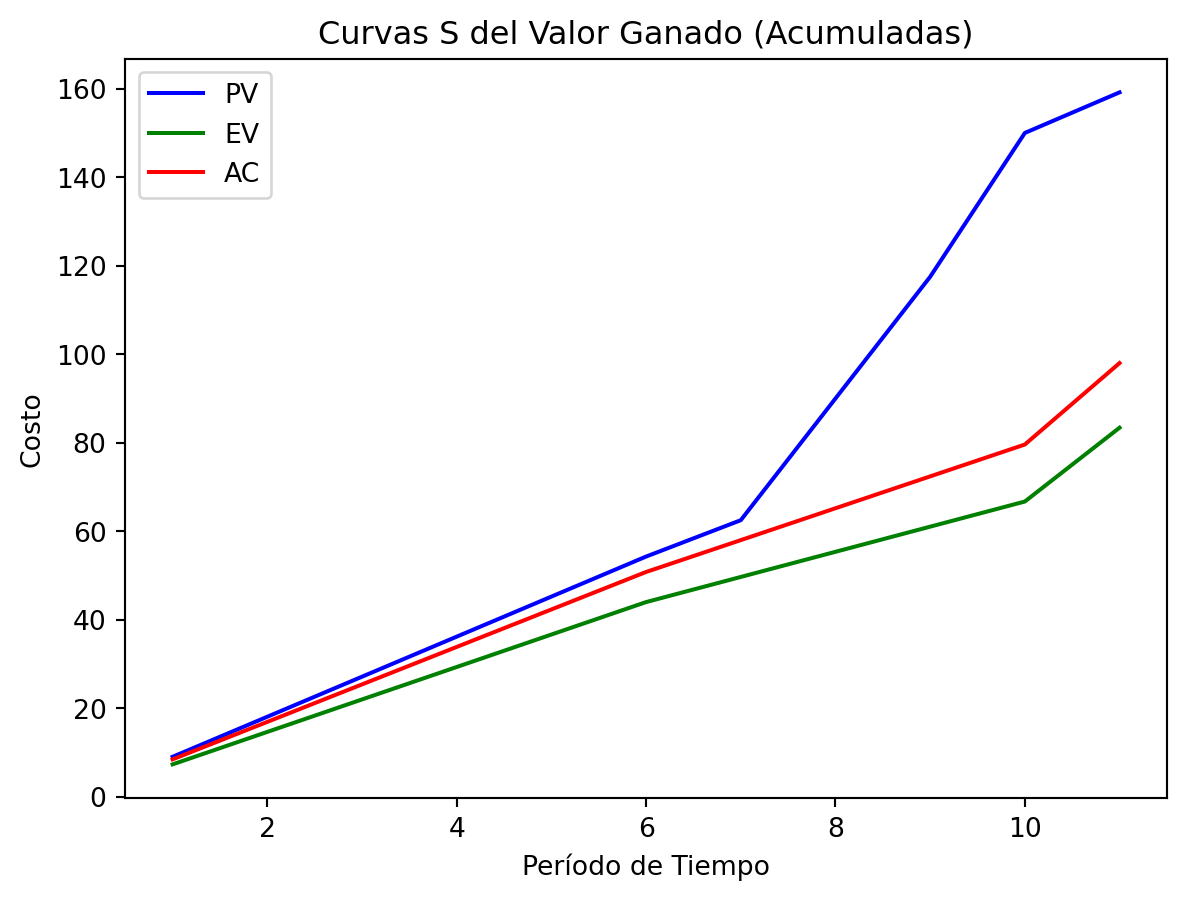

In [62]:
#| fig-cap: "Curvas S del proyecto"
#| label: fig-curvasS-p4
plot_curvas_valor_ganado(gantts)

In [63]:
Markdown(f'''En la semana {semana_control} se ha ganado valor por {EV:.1f} k€ frente a los {PV:.1f} planificados (SV = {SV:.1f}, SPI = {SPI:.2f}: {"retraso" if SPI < 1 else "adelanto"}) y se han gastado {AC:.1f} k€ (CV = {CV:.1f}, CPI = {CPI:.2f}: por cada euro gastado se obtienen {CPI:.2f} euros de valor, {"sobrecoste" if CPI < 1 else "ahorro"}).''')

En la semana 11 se ha ganado valor por 83.4 k€ frente a los 159.2 planificados (SV = -75.8, SPI = 0.52: retraso) y se han gastado 98.0 k€ (CV = -14.6, CPI = 0.85: por cada euro gastado se obtienen 0.85 euros de valor, sobrecoste).

## Apartado 2

In [64]:
display(Markdown(pregunta_2))

2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  

La programación ganada (*Earned Schedule*) busca en qué instante de la planificación se había previsto alcanzar el valor que realmente se ha ganado:

$$ES = C + \frac{EV - PV_C}{PV_{C+1} - PV_C}$$

donde $C$ es la última semana completa con $PV_C \le EV$. Entonces $SPI(t) = ES / AT$, siendo $AT$ el tiempo real transcurrido.

In [65]:
pv_acumulado = pd.concat([pd.Series({0: 0.0}), acumulados['PV'].astype(float)])
C = int(pv_acumulado[pv_acumulado <= EV].index.max())
PV_C, PV_C1 = float(pv_acumulado[C]), float(pv_acumulado[C + 1])
AT = semana_control
ES = C + (EV - PV_C) / (PV_C1 - PV_C)
SPI_t = ES / AT
Markdown(f'PV acumulado en la semana {C}: {PV_C:.1f}; en la {C + 1}: {PV_C1:.1f}. '
         f'ES = {C} + ({EV:.1f} − {PV_C:.1f}) / ({PV_C1:.1f} − {PV_C:.1f}) = {ES:.2f} semanas. '
         f'Retraso = AT − ES = {AT - ES:.2f} semanas; SPI(t) = {ES:.2f} / {AT} = {SPI_t:.2f}.')

PV acumulado en la semana 7: 62.5; en la 8: 90.0. ES = 7 + (83.4 − 62.5) / (90.0 − 62.5) = 7.76 semanas. Retraso = AT − ES = 3.24 semanas; SPI(t) = 7.76 / 11 = 0.71.

## Apartado 3

In [66]:
display(Markdown(pregunta_3))

3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  

In [67]:
PD = duracion_planificada
IEAC_spi = PD / SPI
IEAC_t = PD / SPI_t
pd.DataFrame({'con SPI (€)': [SPI, IEAC_spi], 'con SPI(t) (tiempo)': [SPI_t, IEAC_t]},
             index=['índice', 'duración prevista (semanas)']).round(2)

,con SPI (€),con SPI(t) (tiempo)
índice,0.52,0.71
duración prevista (semanas),41.99,31.19


El SPI en unidades monetarias compara euros ganados con euros planificados, y depende de qué actividades (caras o baratas) estén retrasadas. El SPI(t) compara tiempos: cuántas semanas de avance planificado se han conseguido en las semanas transcurridas. Es más fiable para prever la duración, sobre todo en la segunda mitad del proyecto.

## Apartado 4

In [68]:
display(Markdown(pregunta_4))

4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  

In [69]:
Markdown(f'''Al terminar, EV = BAC y PV = BAC, así que el SPI clásico vale 1 aunque el proyecto haya terminado tarde: pierde su capacidad de aviso conforme avanza el proyecto. El SPI(t) al final vale PD / duración real = {PD} / duración real, que sigue siendo menor que 1 si hubo retraso.''')

Al terminar, EV = BAC y PV = BAC, así que el SPI clásico vale 1 aunque el proyecto haya terminado tarde: pierde su capacidad de aviso conforme avanza el proyecto. El SPI(t) al final vale PD / duración real = 22 / duración real, que sigue siendo menor que 1 si hubo retraso.